# ChainGuard · M4 — Baselines Elliptic et contre-expérience de fuite

**Membre 4 (Laila)** · article : Nayyer et al., IEEE Access 2023 · branche `m4-graph-soc`

Objectifs de la semaine 1 :
1. **6 baselines** sur split temporel : {Random Forest, XGBoost} × {aucun rééquilibrage, SMOTE, ADASYN + TomekLinks}.
2. **2 contre-expériences** qui chiffrent l'optimisme du protocole de Nayyer : rééquilibrage *avant* le split, et split aléatoire au lieu de temporel.
3. La figure-clé du rapport : les 3 protocoles côte à côte.
4. Sauvegarder les prédictions de test, réutilisées pour la dérive (`m4_gnn.ipynb`) et le dashboard Kibana (`m4_seed_kibana.ipynb`).

Protocole commun : rééquilibrage uniquement sur le train dans un `imblearn.Pipeline`, `random_state=42`, métriques de la classe illicite via `src.common.metrics.evaluate`, résultats en JSON dans `results/`.

In [14]:
import sys; sys.path.append('..')

import pathlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from imblearn.over_sampling import ADASYN, SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import TomekLinks
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

from src.common.metrics import evaluate
from src.m4.elliptic import load_elliptic

SEED = 42
RESULTS = pathlib.Path("../results"); RESULTS.mkdir(exist_ok=True)
PROCESSED = pathlib.Path("../data/processed"); PROCESSED.mkdir(parents=True, exist_ok=True)

## 1. Chargement et split temporel

Colonne 0 : `txId`, colonne 1 : période (1 à 49), puis 93 features locales et 72 agrégées (agrégats sur les voisins à 1 saut).
Labels : `1` = illicite, `2` = licite, `unknown` = non étiqueté (exclu de l'entraînement et du test des modèles tabulaires).

**Pourquoi un split temporel.** En production on entraîne sur le passé et on prédit le futur. Un split aléatoire mélange les périodes : le modèle apprend des schémas « du futur ». La coupure 1–34 / 35–49 est celle de Weber et al. (2019).

In [16]:
E = load_elliptic()          # src/m4/elliptic.py : lecture des 3 CSV + split temporel 1–34 / 35–49
df, feat_cols, local_cols = E.df, E.feat_cols, E.local_cols
lab, train, test = E.lab, E.train, E.test
X_tr, y_tr = train[feat_cols], train.y
X_te, y_te = test[feat_cols], test.y

print(f"{len(df):,} transactions, {len(lab):,} étiquetées, {len(feat_cols)} features")
print(f"train : {len(train):,} (illicites {y_tr.mean():.1%}) | test : {len(test):,} (illicites {y_te.mean():.1%})")
# attendu sur le vrai Elliptic : 203 769 transactions, 46 564 étiquetées, environ 10 % d'illicites

203,769 transactions, 46,564 étiquetées, 165 features
train : 29,894 (illicites 11.6%) | test : 16,670 (illicites 6.5%)


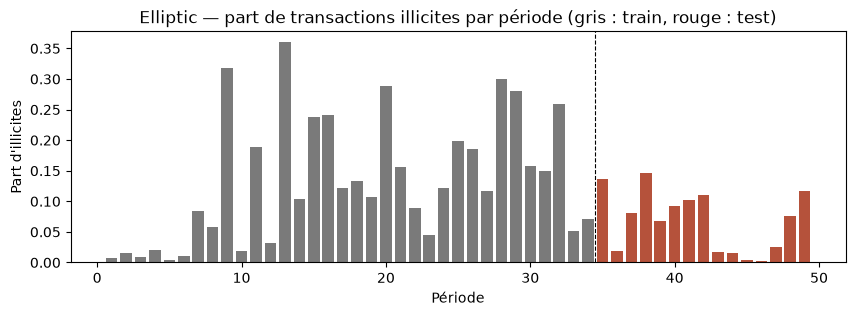

In [17]:
# Part d'illicites par période : utile pour le rapport et pour lire la courbe de dérive
share = lab.groupby("time_step").y.agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(share.index, share["mean"], color=["#7a7a7a" if t <= 34 else "#b5523b" for t in share.index])
ax.axvline(34.5, ls="--", c="black", lw=0.8)
ax.set_xlabel("Période"); ax.set_ylabel("Part d'illicites")
ax.set_title("Elliptic — part de transactions illicites par période (gris : train, rouge : test)")
fig.savefig(RESULTS / "m4_illicit_share.png", dpi=200, bbox_inches="tight")

## 2. Six baselines (bon protocole)

Le rééquilibrage est une étape du `Pipeline` : il ne s'applique qu'au moment du `fit`, donc uniquement sur le train. Le test garde sa distribution réelle.
Repère publié : Weber et al. (2019), F1 illicite ≈ 0.79 avec un Random Forest sur toutes les features. Si on est proche, la base est saine.

In [18]:
variants = {
    "none": [],
    "smote": [("smote", SMOTE(random_state=SEED))],
    "adasyn_tl": [("adasyn", ADASYN(random_state=SEED)), ("tomek", TomekLinks())],   # protocole de Nayyer
}
clfs = {
    "rf": lambda: RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
    "xgb": lambda: XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6,
                                 eval_metric="logloss", n_jobs=-1, random_state=SEED),
}

preds, rows = {}, []
for v, steps in variants.items():
    for m, make in clfs.items():
        name = f"{m}_{v}"
        t0 = time.time()
        pipe = Pipeline(steps + [("clf", make())]).fit(X_tr, y_tr)
        p = pipe.predict_proba(X_te)[:, 1]
        preds[name] = p
        print(f"{name:14s}", end=" ")
        res = evaluate(y_te, (p >= 0.5).astype(int), p, f"m4_{name}", out_dir=str(RESULTS))
        rows.append({**res, "protocole": "temporel, rééq. sur train", "temps_s": round(time.time() - t0, 1)})

rf_none        {'recall': 0.722, 'precision': 0.967, 'f1': 0.827, 'pr_auc': 0.795, 'roc_auc': 0.932}
xgb_none       {'recall': 0.723, 'precision': 0.918, 'f1': 0.809, 'pr_auc': 0.804, 'roc_auc': 0.939}
rf_smote       {'recall': 0.719, 'precision': 0.913, 'f1': 0.805, 'pr_auc': 0.805, 'roc_auc': 0.945}
xgb_smote      {'recall': 0.729, 'precision': 0.891, 'f1': 0.802, 'pr_auc': 0.814, 'roc_auc': 0.946}
rf_adasyn_tl   {'recall': 0.72, 'precision': 0.878, 'f1': 0.791, 'pr_auc': 0.812, 'roc_auc': 0.954}
xgb_adasyn_tl  {'recall': 0.732, 'precision': 0.873, 'f1': 0.797, 'pr_auc': 0.813, 'roc_auc': 0.946}


In [19]:
# Variante utile pour le rapport : RF sur les seules features locales (Weber : F1 ≈ 0.78)
p = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED) \
    .fit(train[local_cols], y_tr).predict_proba(test[local_cols])[:, 1]
preds["rf_none_local"] = p
res = evaluate(y_te, (p >= 0.5).astype(int), p, "m4_rf_none_local", out_dir=str(RESULTS))
rows.append({**res, "protocole": "temporel, features locales", "temps_s": None})

{'recall': 0.713, 'precision': 0.895, 'f1': 0.793, 'pr_auc': 0.782, 'roc_auc': 0.904}


## 3. Contre-expériences : chiffrer la fuite

**(a) Rééquilibrage avant le split** — ce que semble faire Nayyer. Les points synthétiques d'ADASYN sont fabriqués à partir de voisins qui finissent ensuite dans le test : le modèle est évalué sur des quasi-copies de ce qu'il a vu, et le test devient presque équilibré (comme sa Figure 13).

**(b) Split aléatoire stratifié** — pas de suréchantillonnage, mais les périodes sont mélangées : le modèle voit des transactions de la même période (et du même cluster du graphe) que celles du test.

In [20]:
# (a) ERREUR VOLONTAIRE : ADASYN sur tout le jeu étiqueté, PUIS split
X_res, y_res = ADASYN(random_state=SEED).fit_resample(lab[feat_cols], lab.y)
Xa, Xb, ya, yb = train_test_split(X_res, y_res, test_size=0.2, random_state=SEED)
pb = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(Xa, ya).predict_proba(Xb)[:, 1]
res = evaluate(yb, (pb >= 0.5).astype(int), pb, "m4_rf_LEAK_resample_before_split", out_dir=str(RESULTS))
rows.append({**res, "protocole": "rééquilibrage AVANT split", "temps_s": None})
print(f"part d'illicites dans ce « test » : {np.mean(yb):.1%} (vraie distribution : {lab.y.mean():.1%})")

{'recall': 0.997, 'precision': 0.996, 'f1': 0.997, 'pr_auc': 1.0, 'roc_auc': 1.0}
part d'illicites dans ce « test » : 50.5% (vraie distribution : 9.8%)


In [21]:
# (b) Split aléatoire au lieu de temporel
Xa, Xb, ya, yb = train_test_split(lab[feat_cols], lab.y, test_size=0.2, stratify=lab.y, random_state=SEED)
pb = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(Xa, ya).predict_proba(Xb)[:, 1]
res = evaluate(yb, (pb >= 0.5).astype(int), pb, "m4_rf_random_split", out_dir=str(RESULTS))
rows.append({**res, "protocole": "split aléatoire", "temps_s": None})

{'recall': 0.878, 'precision': 0.998, 'f1': 0.934, 'pr_auc': 0.982, 'roc_auc': 0.997}


## 4. Synthèse et figure-clé

In [22]:
summary = pd.DataFrame(rows)[["model", "protocole", "recall", "precision", "f1", "pr_auc", "roc_auc", "temps_s"]]
summary = summary.round(3)
summary.to_csv(RESULTS / "m4_baselines_summary.csv", index=False)
summary

,model,protocole,recall,precision,f1,pr_auc,roc_auc,temps_s
0,m4_rf_none,"temporel, rééq. sur train",0.722,0.967,0.827,0.795,0.932,12.9
1,m4_xgb_none,"temporel, rééq. sur train",0.723,0.918,0.809,0.804,0.939,12.8
2,m4_rf_smote,"temporel, rééq. sur train",0.719,0.913,0.805,0.805,0.945,29.4
3,m4_xgb_smote,"temporel, rééq. sur train",0.729,0.891,0.802,0.814,0.946,17.2
4,m4_rf_adasyn_tl,"temporel, rééq. sur train",0.720,0.878,0.791,0.812,0.954,75.2
5,m4_xgb_adasyn_tl,"temporel, rééq. sur train",0.732,0.873,0.797,0.813,0.946,47.0
6,m4_rf_none_local,"temporel, features locales",0.713,0.895,0.793,0.782,0.904,NaN
7,m4_rf_LEAK_resample_before_split,rééquilibrage AVANT split,0.997,0.996,0.997,1.000,1.000,NaN
8,m4_rf_random_split,split aléatoire,0.878,0.998,0.934,0.982,0.997,NaN


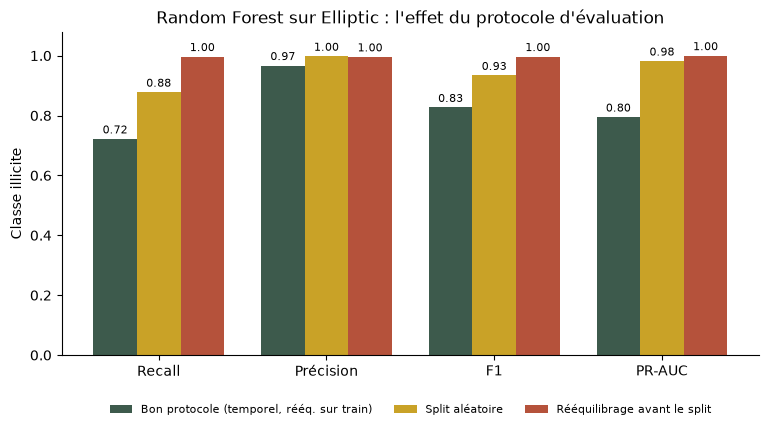

In [23]:
# Figure-clé du rapport : même modèle (RF), trois protocoles
keys = {"Bon protocole\n(temporel, rééq. sur train)": "m4_rf_none",
        "Split aléatoire": "m4_rf_random_split",
        "Rééquilibrage\navant le split": "m4_rf_LEAK_resample_before_split"}
s = summary.set_index("model")
metrics = ["recall", "precision", "f1", "pr_auc"]
colors = ["#3d5a4c", "#c9a227", "#b5523b"]
x = np.arange(len(metrics)); w = 0.26

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (lbl, k) in enumerate(keys.items()):
    vals = s.loc[k, metrics].astype(float).values
    bars = ax.bar(x + (i - 1) * w, vals, w, label=lbl.replace("\n", " "), color=colors[i])
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(x, ["Recall", "Précision", "F1", "PR-AUC"])
ax.set_ylim(0, 1.08); ax.set_ylabel("Classe illicite")
ax.set_title("Random Forest sur Elliptic : l'effet du protocole d'évaluation")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(RESULTS / "m4_leak_comparison.png", dpi=200, bbox_inches="tight")

## 5. Sauvegarde des prédictions de test

Réutilisées par `m4_gnn.ipynb` (courbe de dérive : `rf_none`) et `m4_seed_kibana.ipynb` (alertes : `xgb_none`).

In [24]:
out = test[["txId", "time_step", "y"]].copy()
for k, p in preds.items():
    out[f"p_{k}"] = p
out.to_csv(PROCESSED / "m4_test_preds.csv", index=False)
print(out.shape, "→", PROCESSED / "m4_test_preds.csv")

(16670, 10) → ..\data\processed\m4_test_preds.csv


## 6. Lecture des résultats (à compléter pour le rapport)

- **Meilleure baseline (bon protocole)** : … (F1 = …, PR-AUC = …). Écart avec Weber et al. (0.79) : …
- **Effet du rééquilibrage** : SMOTE / ADASYN-TL améliorent-ils le recall ? Au prix de quelle précision ? Sur Elliptic, ils aident souvent peu, car le test temporel ne ressemble pas au train.
- **Fuite** : F1 bon protocole = … ; split aléatoire = … ; rééquilibrage avant split = …. Le « test » de (a) contient …% d'illicites contre ~10 % en réalité.
- **Message pour le jury** : une partie des scores de Nayyer (F1 0.97) vient probablement du protocole, pas du modèle.